# Notebook 02: Descriptive Statistics and Electricity-Demand Patterns
**Project F1: Electricity Consumption Analysis and Forecasting in Morocco**

## Objective
Describe the level, variability, distribution, and timing of recorded electricity demand across Tetouan's three zones. We use tables and figures as evidence for our team discussion, report, and project defence.

Our questions are:
1. How do demand levels and variability differ across zones?
2. What do the daily, weekly, and monthly patterns look like?
3. When do typical peaks occur, and how do they differ from individual extremes?
4. How strongly do zones move together, and how persistent is demand over time?

## Scope and interpretation
- Input: the checked Parquet file from Notebook 01, covering January 1–December 30, 2017.
- Demand remains in **source units** until the units are verified. We calculate mean demand rather than labelling sums of readings as energy.
- `total` is the simultaneous sum of the three zone readings, assuming comparable units. It represents these zones, not all Moroccan electricity demand.
- This is retrospective exploration of the entire available file. November–December has therefore been viewed descriptively; we must not later describe it as completely unseen. Forecast tuning will use training/validation data, with the limitations of this exploratory exposure disclosed.
- Weather relationships belong in Notebook 03. Forecast horizons and operational peak thresholds will be defined before modelling.
- Serial dependence means 52,416 readings are not 52,416 independent samples. We use descriptive comparisons without independence-based significance claims.

## 1. Setup and Plotting Conventions
Locate the project, import the shared paths, and create separate output folders for this notebook. We use consistent colours for each zone and save every figure as a high-resolution PNG and a scalable SVG.

Run the cells in order using the project's `.venv` kernel. Re-running the notebook replaces its own generated figures and tables.

In [1]:
import sys
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from IPython.display import display

current_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in [current_dir, *current_dir.parents]
     if (p / "src" / "config.py").is_file()), None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open the Project folder containing src/config.py.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.config as cfg
importlib.reload(cfg)
from src.config import PROCESSED_DIR, FIGURES_DIR, TABLES_DIR, ZONES

EDA_FIGURES = FIGURES_DIR / "02_demand_patterns"
EDA_TABLES = TABLES_DIR / "02_demand_patterns"
for folder in [EDA_FIGURES, EDA_TABLES]:
    folder.mkdir(parents=True, exist_ok=True)

SERIES = [*ZONES, "total"]
LABELS = {"zone1": "Zone 1", "zone2": "Zone 2", "zone3": "Zone 3", "total": "Combined"}
COLORS = {"zone1": "#0072B2", "zone2": "#D55E00", "zone3": "#009E73", "total": "#5B3C88"}
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "svg.fonttype": "none"})

def save_table(table, name, index=True):
    table.to_csv(EDA_TABLES / f"{name}.csv", index=index, encoding="utf-8")

def show_figure(fig, name):
    fig.tight_layout()
    fig.savefig(EDA_FIGURES / f"{name}.png", dpi=200, bbox_inches="tight")
    fig.savefig(EDA_FIGURES / f"{name}.svg", bbox_inches="tight")
    plt.show()
    plt.close(fig)

def demand_axis(ax):
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))

print("Python:", sys.executable)
print("Figures:", EDA_FIGURES)
print("Tables :", EDA_TABLES)

Python: C:\Users\banda\Desktop\MScBA\Semester_1\Descriptive Analytics & Data Visualization\Project\.venv\Scripts\python.exe
Figures: C:\Users\banda\Desktop\MScBA\Semester_1\Descriptive Analytics & Data Visualization\Project\outputs\figures\02_demand_patterns
Tables : C:\Users\banda\Desktop\MScBA\Semester_1\Descriptive Analytics & Data Visualization\Project\outputs\tables\02_demand_patterns


## 2. Load the Checked Data and Add Calendar Fields
We recheck the assumptions needed for time-based aggregation, then add hour, weekday, month, and weekend indicators. These fields describe the recorded timestamps; we do not apply timezone conversions.

The cleaned Parquet file is read without modification. New columns exist only in this notebook's dataframe.

In [2]:
clean_path = PROCESSED_DIR / "tetuan_clean.parquet"
df = pd.read_parquet(clean_path)
assert len(df) == 52_416 and df.shape[1] == 9
assert pd.api.types.is_datetime64_any_dtype(df["datetime"])
assert df["datetime"].is_unique and df["datetime"].is_monotonic_increasing
assert df["datetime"].min() == pd.Timestamp("2017-01-01 00:00")
assert df["datetime"].max() == pd.Timestamp("2017-12-30 23:50")
assert df["datetime"].diff().dropna().eq(pd.Timedelta("10min")).all()
assert not df.isna().any().any()
assert np.isfinite(df.select_dtypes(include="number").to_numpy()).all()
assert df[ZONES].gt(0).all().all()

df["total"] = df[ZONES].sum(axis=1)
df["hour"] = df["datetime"].dt.hour
df["weekday"] = df["datetime"].dt.day_of_week
df["month"] = df["datetime"].dt.month
df["is_weekend"] = df["weekday"].ge(5)
df["day_type"] = np.where(df["is_weekend"], "Weekend", "Weekday")
ts = df.set_index("datetime")[SERIES]
daily = ts.resample("D").mean()
assert len(daily) == 364
assert ts.resample("D").size().eq(144).all()

print(f"Loaded {len(df):,} readings across {len(daily)} complete days.")
print("Period:", ts.index.min(), "to", ts.index.max())
display(df.head())

Loaded 52,416 readings across 364 complete days.
Period: 2017-01-01 00:00:00 to 2017-12-30 23:50:00


,datetime,temperature,humidity,wind_speed,general_diffuse_flows,diffuse_flows,zone1,zone2,zone3,total,hour,weekday,month,is_weekend,day_type
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386,70425.53544,0,6,1,True,Weekend
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434,69320.84387,0,6,1,True,Weekend
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373,67803.22193,0,6,1,True,Weekend
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711,65489.23209,0,6,1,True,Weekend
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964,63650.44627,0,6,1,True,Weekend


### Interpretation: Available Observations
We have 364 complete days and 144 readings per day. December contains 30 days; every other month is complete. December 31 remains absent and is not filled.

Because each observed day has the same number of readings, averaging ten-minute observations within a month gives the same monthly mean as averaging its daily means. We still report monthly observation counts so that coverage is visible.

## 3. Descriptive Statistics
First inspect all original numeric variables, including weather for context. The detailed demand table then includes:
- **Mean and median:** average and middle demand.
- **Standard deviation and variance:** absolute spread around the mean; sample formulas use `ddof=1`.
- **Coefficient of variation (CV):** standard deviation divided by mean, expressed as a percentage, for relative variability.
- **Percentiles and IQR:** distribution landmarks; IQR is the 75th minus the 25th percentile.
- **Skewness:** positive values indicate a longer upper tail.
- **Excess kurtosis:** a shape diagnostic relative to a normal distribution, whose excess kurtosis is zero.

The 95th and 99th percentiles here describe the full historical file. They are not operational alert thresholds and must not be reused as training-derived thresholds.

In [3]:
original_numeric = ["temperature", "humidity", "wind_speed", "general_diffuse_flows", "diffuse_flows", *ZONES]
overview = df[original_numeric].describe().T
save_table(overview, "01_all_numeric_overview")
display(overview.round(2))

stats = ts.describe(percentiles=[.05, .25, .50, .75, .95, .99]).T
stats = stats.rename(columns={"50%": "median", "5%": "p05", "25%": "p25",
                             "75%": "p75", "95%": "p95", "99%": "p99"})
stats["variance"] = ts.var(ddof=1)
stats["range"] = stats["max"] - stats["min"]
stats["iqr"] = stats["p75"] - stats["p25"]
stats["cv_pct"] = stats["std"] / stats["mean"] * 100
stats["skewness"] = ts.skew()
stats["excess_kurtosis"] = ts.kurt()
save_table(stats, "02_demand_statistics")
display(stats[["count", "mean", "median", "min", "max"]].round(2))
display(stats[["std", "variance", "range", "iqr", "cv_pct"]].round(2))
display(stats[["p05", "p25", "p75", "p95", "p99", "skewness", "excess_kurtosis"]].round(2))

,count,mean,std,min,25%,50%,75%,max
temperature,52416.0,18.81,5.82,3.25,14.41,18.78,22.89,40.01
humidity,52416.0,68.26,15.55,11.34,58.31,69.86,81.40,94.80
wind_speed,52416.0,1.96,2.35,0.05,0.08,0.09,4.92,6.48
general_diffuse_flows,52416.0,182.70,264.40,0.00,0.06,5.04,319.60,1163.00
diffuse_flows,52416.0,75.03,124.21,0.01,0.12,4.46,101.00,936.00
zone1,52416.0,32344.97,7130.56,13895.70,26310.67,32265.92,37309.02,52204.40
zone2,52416.0,21042.51,5201.47,8560.08,16980.77,20823.17,24713.72,37408.86
zone3,52416.0,17835.41,6622.17,5935.17,13129.33,16415.12,21624.10,47598.33


,count,mean,median,min,max
zone1,52416.0,32344.97,32265.92,13895.70,52204.40
zone2,52416.0,21042.51,20823.17,8560.08,37408.86
zone3,52416.0,17835.41,16415.12,5935.17,47598.33
total,52416.0,71222.89,69788.79,36785.04,134208.15


,std,variance,range,iqr,cv_pct
zone1,7130.56,5.084492e+07,38308.70,10998.35,22.05
zone2,5201.47,2.705525e+07,28848.78,7732.95,24.72
zone3,6622.17,4.385307e+07,41663.15,8494.77,37.13
total,17143.14,2.938872e+08,97423.11,27250.10,24.07


,p05,p25,p75,p95,p99,skewness,excess_kurtosis
zone1,21867.34,26310.67,37309.02,44712.06,48099.48,0.23,-0.75
zone2,13284.15,16980.77,24713.72,30387.14,33734.95,0.33,-0.44
zone3,9519.33,13129.33,21624.10,29905.71,38722.44,1.02,1.09
total,48027.05,56499.07,83749.17,99374.48,118088.23,0.52,-0.23


### Interpretation: Demand Levels and Variability
- Mean demand is **32,344.97** in Zone 1, **21,042.51** in Zone 2, and **17,835.41** in Zone 3. Combined mean demand is **71,222.89 source units**.
- Zone 1 has the largest absolute standard deviation, approximately **7,130.56**.
- Zone 3 has the largest relative variability: its CV is approximately **37.13%**, compared with **22.05%** in Zone 1 and **24.72%** in Zone 2.
- Zone 3 is also more right-skewed (**1.02**), indicating a more pronounced upper tail.

The largest zone is therefore not automatically the most variable relative to its own mean. CV and standard deviation answer different questions. These statistics describe the file and do not by themselves determine which zone will be hardest to forecast.

## 4. Demand Across the Observed Period
The upper panel shows daily combined mean demand, with the daily minimum-to-maximum range shaded. The lower panel compares daily zone means.

Each mean averages 144 ten-minute readings. The shaded band is observed within-day variation, not a confidence interval or forecast interval.

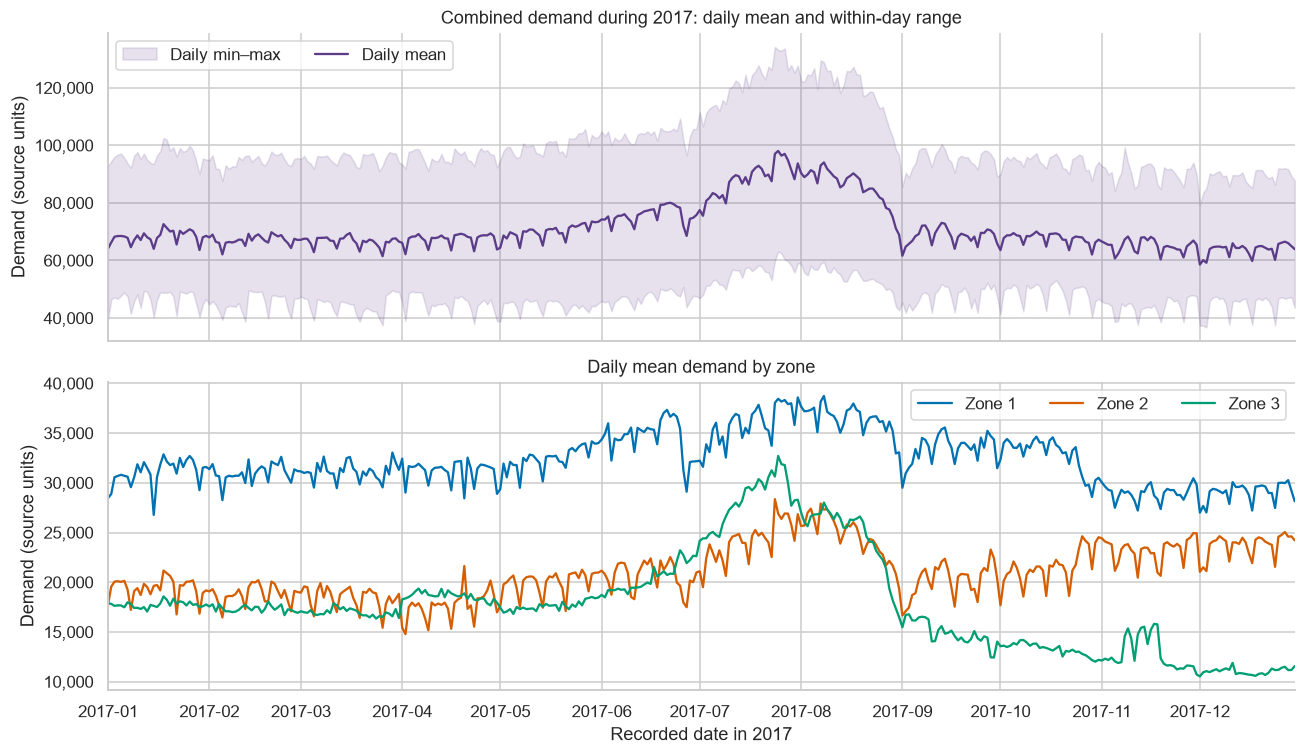

In [4]:
daily_min = ts.resample("D").min()
daily_max = ts.resample("D").max()
save_table(daily, "03_daily_mean_demand")
save_table(daily_max - daily_min, "04_daily_demand_range")

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].fill_between(daily.index, daily_min["total"], daily_max["total"],
                     color=COLORS["total"], alpha=.15, label="Daily min–max")
axes[0].plot(daily.index, daily["total"], color=COLORS["total"], label="Daily mean")
axes[0].set(title="Combined demand during 2017: daily mean and within-day range", ylabel="Demand (source units)")
axes[0].legend(loc="upper left", ncol=2)
for zone in ZONES:
    axes[1].plot(daily.index, daily[zone], color=COLORS[zone], label=LABELS[zone])
axes[1].set(title="Daily mean demand by zone", ylabel="Demand (source units)", xlabel="Recorded date in 2017")
axes[1].legend(ncol=3)
axes[1].set_xlim(daily.index.min(), daily.index.max())
for ax in axes:
    demand_axis(ax)
show_figure(fig, "01_daily_demand_overview")

### Interpretation: Changes Through the Year
Combined demand rises during the middle of the year, with elevated daily means in July and August. Zone 3 shows a particularly marked summer increase and lower levels toward the end of the observed period.

These movements motivate comparisons by month and zone. They do not establish a weather effect, a customer type, or a cause. We will examine weather associations separately.

## 5. Distributions and Duration Curves
Histograms show how frequently demand falls within different ranges. Each panel has its own scale because zone demand and combined demand differ in magnitude.

Boxplots show the median, IQR, and observations beyond the usual 1.5 × IQR whiskers. Points beyond the whiskers are descriptive extremes, not automatic data errors.

A demand-duration curve sorts readings from largest to smallest. It shows the fraction of observed time associated with different demand levels, while discarding chronological order. Equal ten-minute spacing makes percentages of readings percentages of observed time.

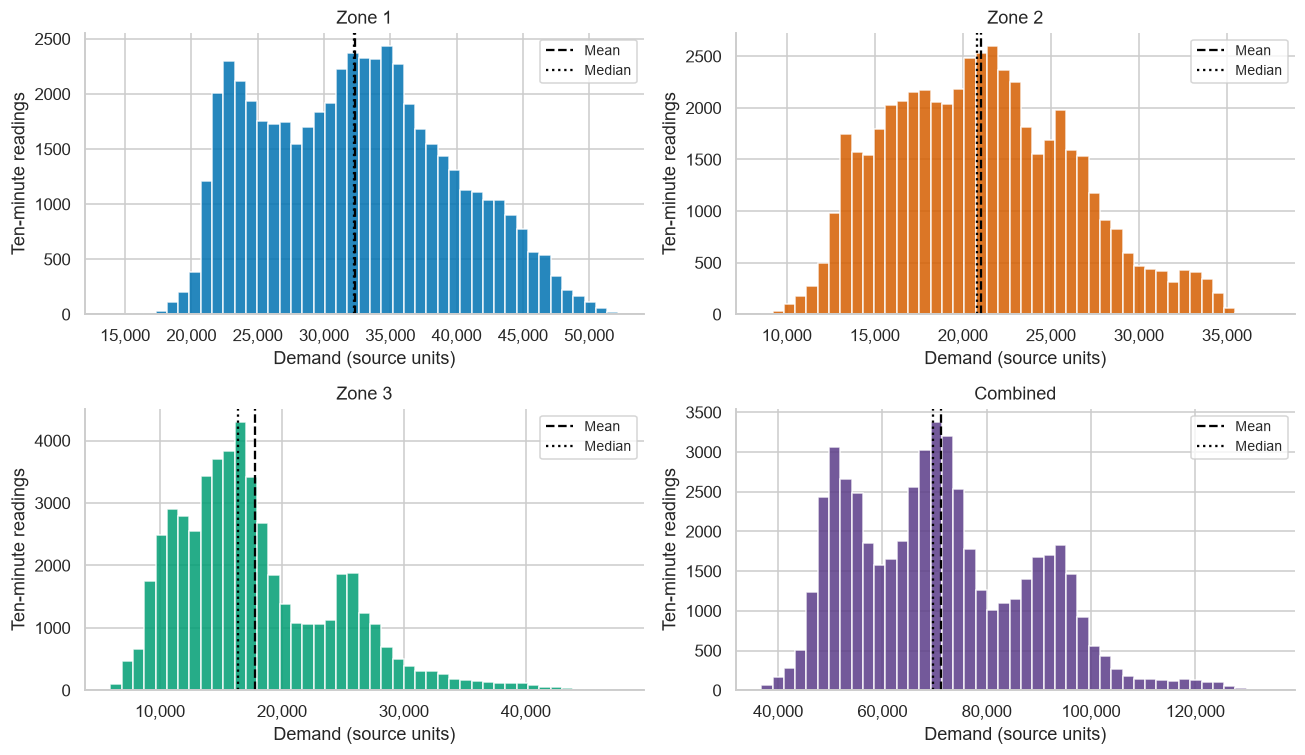

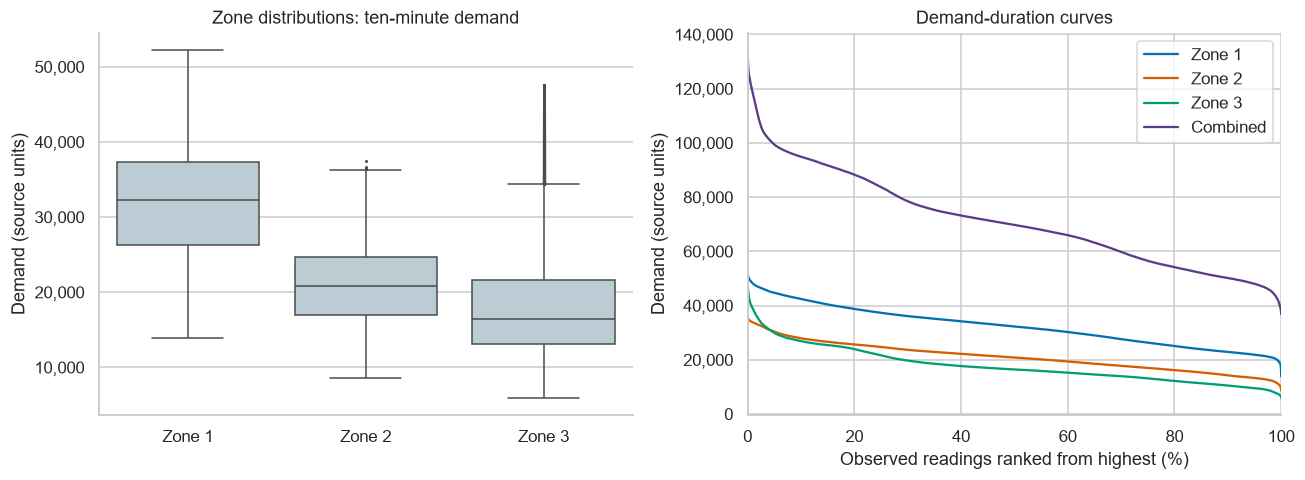

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, series in zip(axes.flat, SERIES):
    ax.hist(ts[series], bins=45, color=COLORS[series], alpha=.85, edgecolor="white")
    ax.axvline(ts[series].mean(), color="black", linestyle="--", label="Mean")
    ax.axvline(ts[series].median(), color="black", linestyle=":", label="Median")
    ax.set(title=LABELS[series], xlabel="Demand (source units)", ylabel="Ten-minute readings")
    ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
    ax.legend(fontsize=9)
show_figure(fig, "02_demand_histograms")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=df[ZONES], ax=axes[0], color="#B8CDD9", fliersize=1)
axes[0].set_xticks(range(3), [LABELS[z] for z in ZONES])
axes[0].set(title="Zone distributions: ten-minute demand", ylabel="Demand (source units)")
for series in SERIES:
    ordered = np.sort(ts[series].to_numpy())[::-1]
    fraction = np.arange(1, len(ordered) + 1) / len(ordered) * 100
    axes[1].plot(fraction, ordered, color=COLORS[series], label=LABELS[series])
axes[1].set(title="Demand-duration curves", xlabel="Observed readings ranked from highest (%)", ylabel="Demand (source units)", xlim=(0, 100))
axes[1].legend()
for ax in axes:
    demand_axis(ax)
show_figure(fig, "03_boxplots_and_duration_curves")

### Interpretation: Distribution Shape
Zone 1 generally operates at a higher demand level. Zone 3 combines a lower typical level with a more pronounced upper tail, consistent with its higher CV and positive skewness.

The duration curves help distinguish demand maintained across much of the observed period from high demand occurring for shorter periods. They do not show when those periods occurred; timestamps are needed for that question.

The distribution pools different hours and months, so its shape mixes daily and monthly patterns. We should not assume a single normal distribution for every operating condition.

## 6. Typical Hourly Demand
Group observations by recorded hour, then average across the available days. For example, hour 20 includes observations from 20:00 through 20:50 on each observed day.

The combined-demand panel also shows the 25th–75th percentile range of individual ten-minute readings within each hour. This band describes historical variability, not uncertainty about the mean.

Highest hourly mean: 20:00–20:50 = 98,037.11
Lowest hourly mean : 06:00–06:50 = 50,189.90


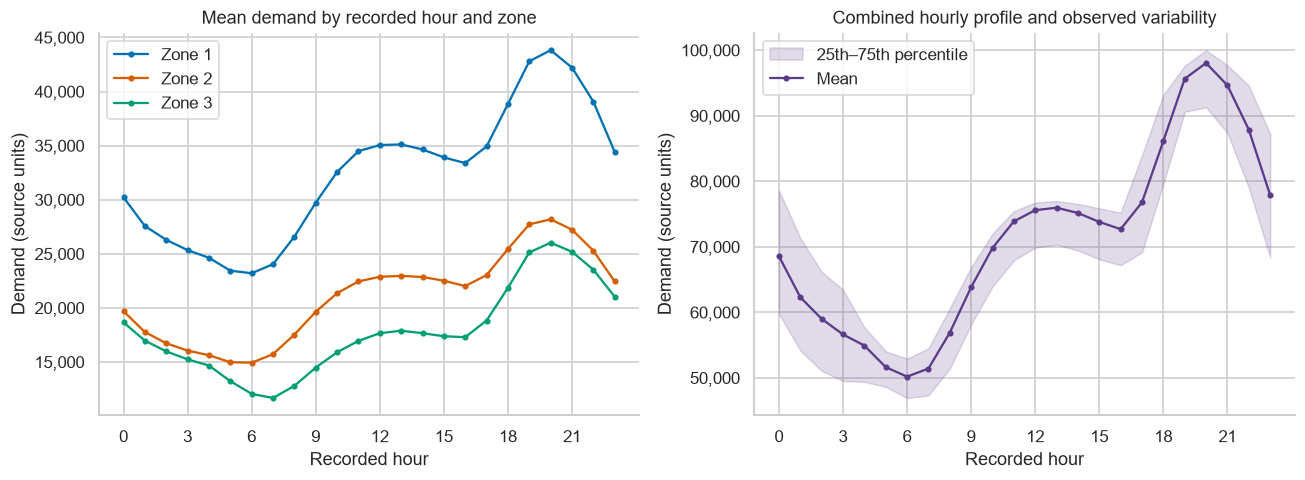

In [6]:
hourly = df.groupby("hour")[SERIES].mean().reindex(range(24))
hourly_iqr = df.groupby("hour")["total"].quantile([.25, .75]).unstack()
save_table(hourly, "05_hourly_mean_demand")
save_table(hourly_iqr, "06_hourly_combined_quartiles")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for zone in ZONES:
    axes[0].plot(hourly.index, hourly[zone], marker="o", markersize=3,
                 color=COLORS[zone], label=LABELS[zone])
axes[0].set(title="Mean demand by recorded hour and zone")
axes[0].legend()
axes[1].fill_between(hourly_iqr.index, hourly_iqr[.25], hourly_iqr[.75],
                     color=COLORS["total"], alpha=.18, label="25th–75th percentile")
axes[1].plot(hourly.index, hourly["total"], color=COLORS["total"], marker="o", markersize=3, label="Mean")
axes[1].set(title="Combined hourly profile and observed variability")
axes[1].legend()
for ax in axes:
    ax.set(xlabel="Recorded hour", ylabel="Demand (source units)", xticks=range(0, 24, 3))
    demand_axis(ax)
show_figure(fig, "04_hourly_profiles")

print(f"Highest hourly mean: {hourly['total'].idxmax():02d}:00–{hourly['total'].idxmax():02d}:50 = {hourly['total'].max():,.2f}")
print(f"Lowest hourly mean : {hourly['total'].idxmin():02d}:00–{hourly['total'].idxmin():02d}:50 = {hourly['total'].min():,.2f}")

### Interpretation: Typical Peak and Low-Demand Hours
The highest combined hourly mean occurs during **20:00–20:50**, at **98,037.11**. The lowest occurs during **06:00–06:50**, at **50,189.90 source units**.

The evening hourly mean is approximately **95.33% higher** than the lowest hourly mean. This is an average daily profile, not the maximum individual reading and not a forecast.

Hour-of-day features are therefore sensible candidates for later forecasting. Their usefulness must still be evaluated against baseline models.

## 7. Weekday and Weekend Comparisons
We compare average demand across all seven weekdays, then compare weekday and weekend hourly profiles. Weekend means Saturday and Sunday; this is a calendar grouping rather than a verified operational schedule.

We report day counts as well as means. Differences are descriptive and may also reflect the mix of months, weather, holidays, or other unmeasured factors.

Weekend mean relative to weekday mean: -3.77%


,zone1,zone2,zone3,total,observed_days
weekday,,,,,
Monday,32615.41,21280.07,17809.08,71704.56,52
Tuesday,32713.03,21518.60,17831.69,72063.32,52
Wednesday,32871.76,21627.36,17851.40,72350.52,52
Thursday,32842.48,21845.16,17843.69,72531.34,52
Friday,32339.00,21461.04,17545.97,71346.01,52
Saturday,32253.03,20585.96,18011.19,70850.18,52
Sunday,30780.08,18979.38,17954.83,67714.28,52


,zone1,zone2,zone3,total,observed_days
day_type,,,,,
Weekday,32676.34,21546.45,17776.37,71999.15,260
Weekend,31516.56,19782.67,17983.01,69282.23,104


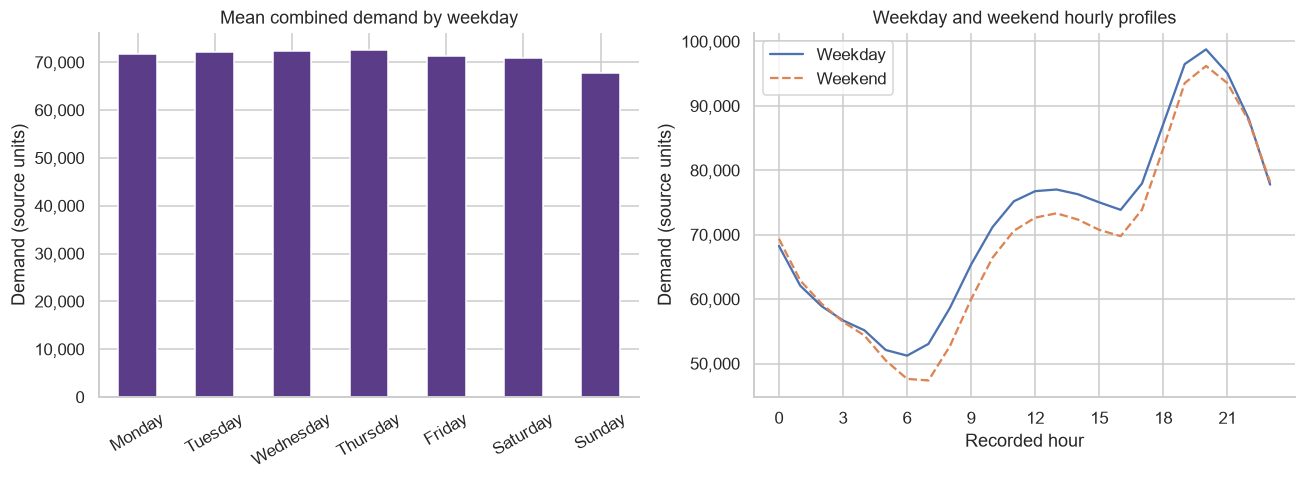

In [7]:
weekday = df.groupby("weekday")[SERIES].mean().reindex(range(7))
weekday.index = pd.Index(WEEKDAYS, name="weekday")
day_counts = daily.groupby(daily.index.day_of_week).size()
weekday_counts = pd.Series(day_counts.to_numpy(), index=weekday.index, name="observed_days")
save_table(weekday.join(weekday_counts), "07_weekday_means_and_counts")
display(weekday.join(weekday_counts).round(2))

weekend_stats = df.groupby("day_type")[SERIES].mean().reindex(["Weekday", "Weekend"])
weekend_stats["observed_days"] = df.groupby("day_type").size().reindex(weekend_stats.index) // 144
save_table(weekend_stats, "08_weekday_weekend_means")
display(weekend_stats.round(2))
weekend_hour = df.groupby(["day_type", "hour"])["total"].mean().unstack("day_type")
save_table(weekend_hour, "09_weekday_weekend_hourly_means")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
weekday["total"].plot.bar(ax=axes[0], color=COLORS["total"], rot=30)
axes[0].set(title="Mean combined demand by weekday", xlabel="", ylabel="Demand (source units)")
for kind, style in [("Weekday", "-"), ("Weekend", "--")]:
    axes[1].plot(weekend_hour.index, weekend_hour[kind], linestyle=style, label=kind)
axes[1].set(title="Weekday and weekend hourly profiles", xlabel="Recorded hour", ylabel="Demand (source units)", xticks=range(0,24,3))
axes[1].legend()
for ax in axes:
    demand_axis(ax)
show_figure(fig, "05_weekday_and_weekend_patterns")
gap = (weekend_stats.loc["Weekend", "total"] / weekend_stats.loc["Weekday", "total"] - 1) * 100
print(f"Weekend mean relative to weekday mean: {gap:.2f}%")

### Interpretation: Weekly Pattern
Sunday has the lowest combined weekday mean, approximately **67,714.28**, while Thursday has the highest, approximately **72,531.34 source units**.

All seven weekdays occur **52 times** in the observed file, so the seven weekday averages have equal numbers of daily observations.

Combined weekend mean demand is **69,282.23**, compared with **71,999.15** on weekdays, a difference of approximately **3.77% below** the weekday mean. Zone 3 is an exception to the overall direction: its weekend mean is slightly higher than its weekday mean.

The weekday/weekend plot shows whether the difference varies by hour. A lower weekend average does not mean every weekend reading is below every weekday reading, and it does not establish that working schedules caused the difference.

## 8. Monthly Patterns and Within-Month Variation
Monthly means describe broad changes. Boxplots of **daily combined means** show how much day-to-day variation exists within each month.

The boxplots use 28–31 daily observations per month, rather than treating all ten-minute readings as independent days. December contributes 30 days.

July mean: 88,173.55; December mean: 63,750.83
July relative to December: 38.31% higher


,zone1,zone2,zone3,total,readings,observed_days
month,,,,,,
1,31032.49,19394.44,17746.10,68173.03,4464,31
2,30985.75,18787.79,17335.00,67108.55,4032,28
3,31155.17,18457.94,16947.69,66560.79,4464,31
4,31169.77,17633.97,18593.17,67396.90,4320,30
5,32396.01,19977.29,17621.10,69994.40,4464,31
6,34605.54,20670.93,20430.94,75707.41,4320,30
7,35831.55,24147.89,28194.11,88173.55,4464,31
8,36435.19,24656.22,24648.89,85740.30,4464,31
9,33396.68,20180.43,14922.80,68499.91,4320,30


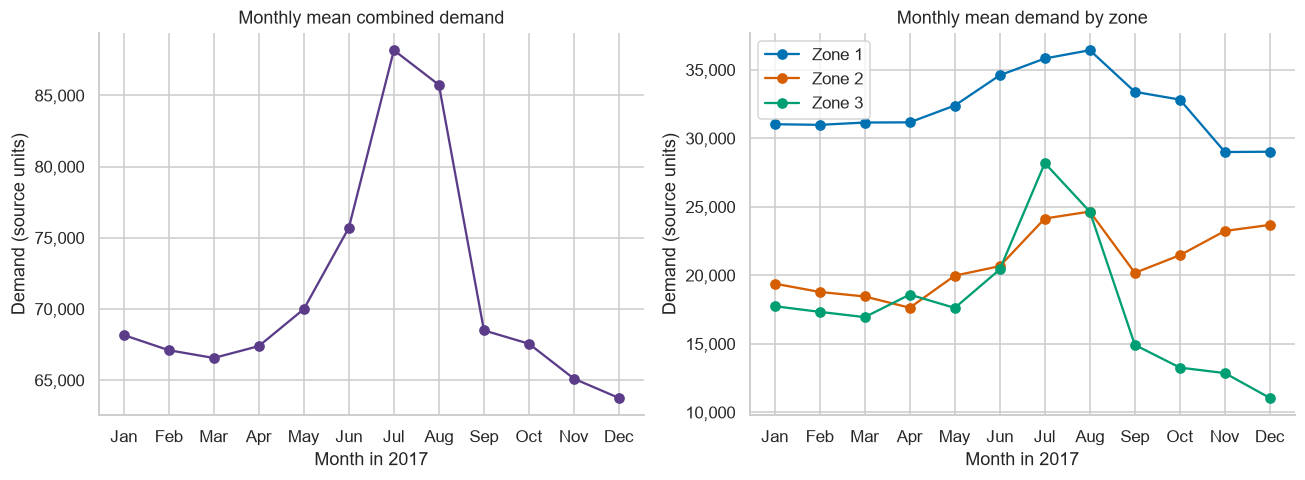

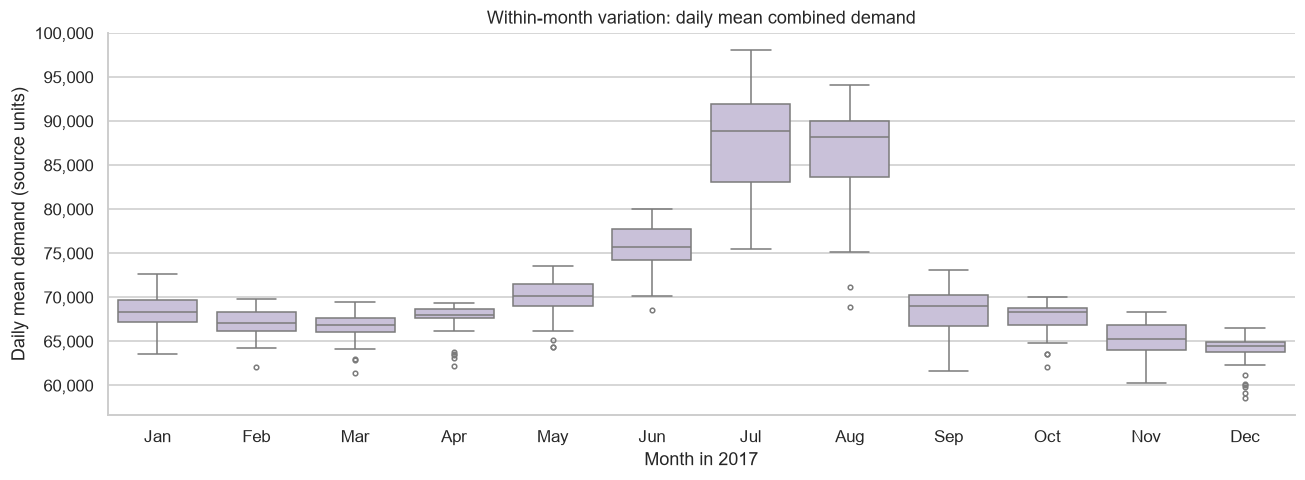

In [8]:
monthly = df.groupby("month")[SERIES].mean().reindex(range(1,13))
monthly_coverage = df.groupby("month").size().rename("readings").to_frame()
monthly_coverage["observed_days"] = monthly_coverage["readings"] // 144
monthly_report = monthly.join(monthly_coverage)
save_table(monthly_report, "10_monthly_means_and_coverage")
display(monthly_report.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(monthly.index, monthly["total"], marker="o", color=COLORS["total"])
axes[0].set(title="Monthly mean combined demand")
for zone in ZONES:
    axes[1].plot(monthly.index, monthly[zone], marker="o", color=COLORS[zone], label=LABELS[zone])
axes[1].set(title="Monthly mean demand by zone")
axes[1].legend()
for ax in axes:
    ax.set(xlabel="Month in 2017", ylabel="Demand (source units)", xticks=range(1,13), xticklabels=MONTHS)
    demand_axis(ax)
show_figure(fig, "06_monthly_mean_profiles")

daily_plot = daily.reset_index()
daily_plot["month"] = daily_plot["datetime"].dt.month
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.boxplot(data=daily_plot, x="month", y="total", color="#C8BDDD", ax=ax, fliersize=3)
ax.set(title="Within-month variation: daily mean combined demand", xlabel="Month in 2017", ylabel="Daily mean demand (source units)")
ax.set_xticks(range(12), MONTHS)
demand_axis(ax)
show_figure(fig, "07_monthly_distribution_of_daily_means")
save_table(daily_plot.groupby("month")["total"].describe(), "11_monthly_daily_mean_statistics")

print(f"July mean: {monthly.loc[7,'total']:,.2f}; December mean: {monthly.loc[12,'total']:,.2f}")
print(f"July relative to December: {(monthly.loc[7,'total']/monthly.loc[12,'total']-1)*100:.2f}% higher")

### Interpretation: Monthly Differences
July has the highest combined monthly mean, **88,173.55**, and December the lowest, **63,750.83 source units**. July is approximately **38.31% higher** than December.

Zone 3 rises to a July mean of **28,194.11**, compared with **11,044.81** in December. Zone 2's monthly mean rises again from September toward December, while the zones' patterns are not identical.

The boxplots preserve the variation hidden by monthly averages. With only one observed year, we describe these as **monthly patterns during 2017**, not proof of a stable repeating annual cycle. December's missing final day also limits the calendar-month comparison.

## 9. Each Zone's Share of Combined Demand
The overall contribution uses each zone's sum of readings divided by the combined sum across identical timestamps. With equal spacing and complete matched coverage, this is also each zone's mean divided by the combined mean.

Monthly shares use the same calculation within each month. These are relative contributions across the three observed zones; they are not market shares or measured energy totals. A larger share can arise because one zone rises or because another falls.

,share_pct
zone1,45.41
zone2,29.54
zone3,25.04


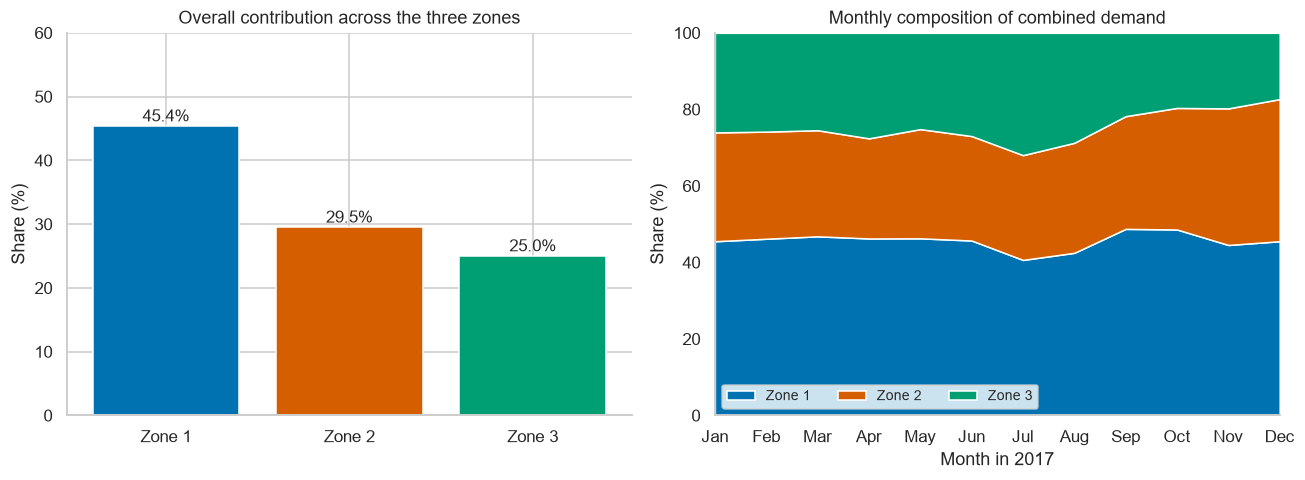

In [9]:
overall_share = (ts[ZONES].sum() / ts["total"].sum() * 100).rename("share_pct")
monthly_share = monthly[ZONES].div(monthly["total"], axis=0) * 100
assert np.isclose(overall_share.sum(), 100)
assert np.allclose(monthly_share.sum(axis=1), 100)
save_table(overall_share, "12_overall_zone_shares")
save_table(monthly_share, "13_monthly_zone_shares")
display(overall_share.round(2).to_frame())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar([LABELS[z] for z in ZONES], overall_share, color=[COLORS[z] for z in ZONES])
for i, value in enumerate(overall_share):
    axes[0].text(i, value + .7, f"{value:.1f}%", ha="center")
axes[0].set(title="Overall contribution across the three zones", ylabel="Share (%)", ylim=(0,60))
axes[1].stackplot(monthly_share.index, *[monthly_share[z] for z in ZONES],
                  labels=[LABELS[z] for z in ZONES], colors=[COLORS[z] for z in ZONES])
axes[1].set(title="Monthly composition of combined demand", xlabel="Month in 2017", ylabel="Share (%)", ylim=(0,100), xlim=(1,12), xticks=range(1,13), xticklabels=MONTHS)
axes[1].legend(loc="lower left", ncol=3, fontsize=9)
show_figure(fig, "08_zone_contributions")

### Interpretation: Zone Contributions
Zone 1 contributes approximately **45.41%**, Zone 2 **29.54%**, and Zone 3 **25.04%** of combined readings over the observed period. Rounded shares may not sum to exactly 100%.

Zone 1 contributes the largest share overall. The monthly composition changes, so a single annual percentage would hide important differences across the year. We should preserve separate zone analysis when building forecasts and the dashboard.

## 10. Hour-by-Month and Hour-by-Weekday Heatmaps
Heatmaps reveal interactions that separate monthly or hourly averages can hide.

The first figure compares hour-by-month means for all three zones. All zone panels share one colour scale, so colours are comparable in absolute source units. The second figure shows the combined hour-by-weekday profile.

Each cell is a mean across its matching ten-minute observations. These figures describe observed demand and do not mark operational peak alerts.

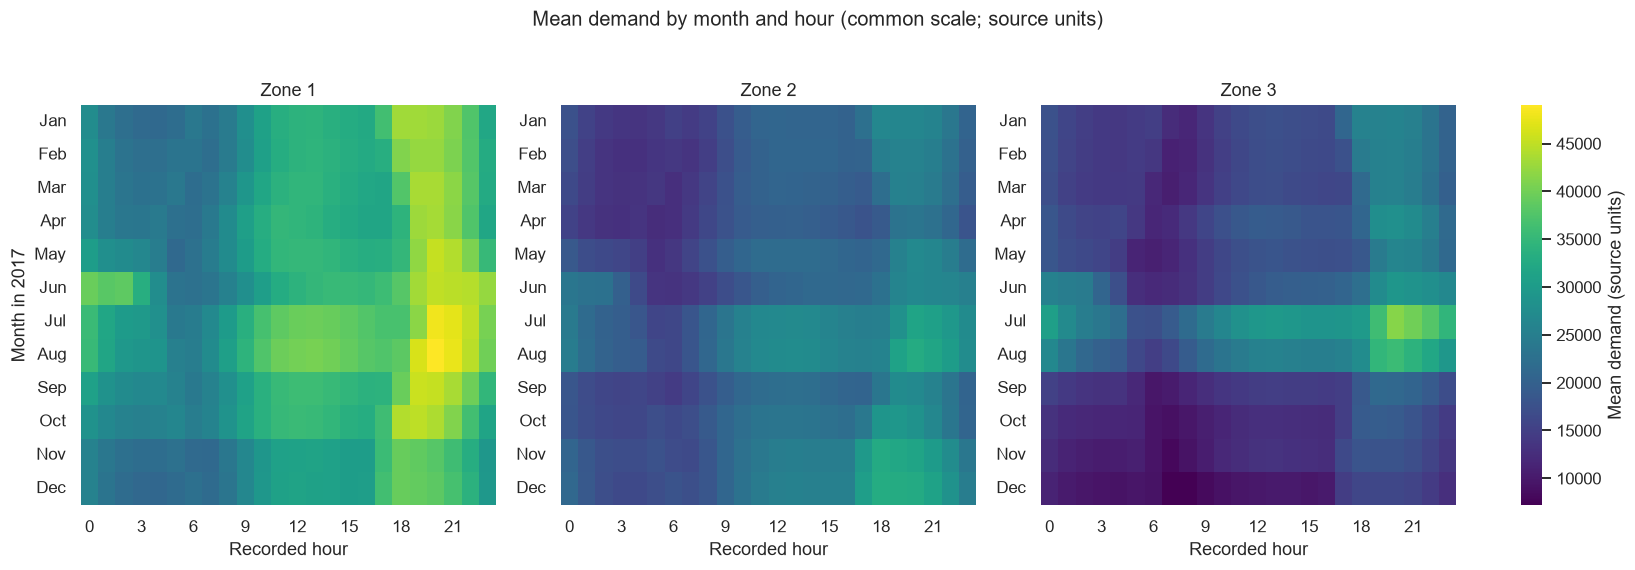

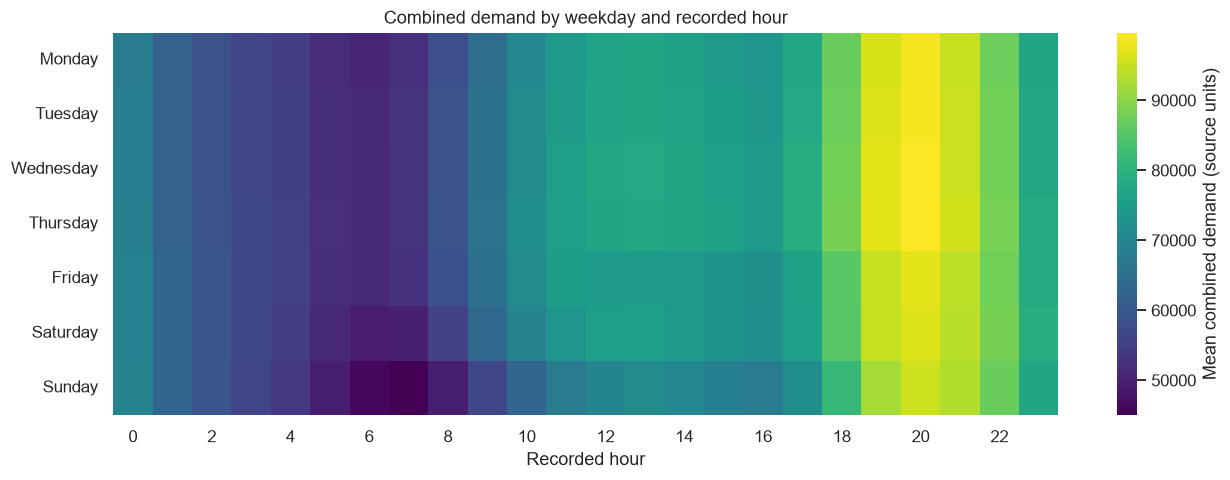

In [10]:
zone_month_hour = {
    z: df.pivot_table(index="month", columns="hour", values=z, aggfunc="mean").reindex(index=range(1,13), columns=range(24))
    for z in ZONES
}
vmin = min(p.to_numpy().min() for p in zone_month_hour.values())
vmax = max(p.to_numpy().max() for p in zone_month_hour.values())
fig = plt.figure(figsize=(15, 5))
grid = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1, .05])
axes = [fig.add_subplot(grid[0, i]) for i in range(3)]
color_ax = fig.add_subplot(grid[0, 3])
for ax, zone in zip(axes, ZONES):
    pivot = zone_month_hour[zone]
    sns.heatmap(pivot, ax=ax, cmap="viridis", vmin=vmin, vmax=vmax,
                cbar=(zone == ZONES[-1]), cbar_ax=color_ax if zone == ZONES[-1] else None,
                cbar_kws={"label": "Mean demand (source units)"},
                xticklabels=3, yticklabels=MONTHS)
    ax.set(title=LABELS[zone], xlabel="Recorded hour", ylabel="Month in 2017" if zone == ZONES[0] else "")
    ax.tick_params(axis="y", rotation=0)
    save_table(pivot, f"14_month_hour_{zone}")
fig.suptitle("Mean demand by month and hour (common scale; source units)", y=1.03)
show_figure(fig, "09_zone_month_hour_heatmaps")

week_hour = df.pivot_table(index="weekday", columns="hour", values="total", aggfunc="mean").reindex(index=range(7), columns=range(24))
week_hour.index = WEEKDAYS
save_table(week_hour, "15_combined_weekday_hour")
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.heatmap(week_hour, ax=ax, cmap="viridis", xticklabels=2, yticklabels=WEEKDAYS,
            cbar_kws={"label": "Mean combined demand (source units)"})
ax.set(title="Combined demand by weekday and recorded hour", xlabel="Recorded hour", ylabel="")
ax.tick_params(axis="y", rotation=0)
show_figure(fig, "10_combined_weekday_hour_heatmap")

### Interpretation: Interacting Time Patterns
The heatmaps show that demand depends on combinations of time categories. The evening pattern appears across weekdays, while the month-by-hour panels reveal differences in both level and timing across zones.

Using a common scale prevents a low-demand zone from appearing as high as a larger zone simply because its colours were rescaled independently. However, small within-zone differences can be less visible on that common scale; the earlier line charts help interpret them.

For a defence, explain what one cell represents before discussing its colour: for example, the mean of all Zone 1 readings recorded during a particular hour in a particular month.

## 11. Individual Extremes and Short-Term Changes
Find the largest and smallest combined readings and the five highest distinct daily maxima. Ranking distinct days avoids presenting adjacent readings from one event as several separate events. The zone readings shown in the top-days table are taken at the same timestamp as each combined maximum, rather than each zone's separate daily maximum.

Ten-minute changes describe short-term movement: current reading minus the preceding reading. We summarise their absolute magnitudes and list the largest combined changes. Causes cannot be identified from these calculations alone.

In [11]:
extremes = pd.concat([
    df.loc[df["total"].idxmax(), ["datetime", *SERIES]].to_frame().T.assign(event="Maximum combined reading"),
    df.loc[df["total"].idxmin(), ["datetime", *SERIES]].to_frame().T.assign(event="Minimum combined reading")
], ignore_index=True)
save_table(extremes, "16_individual_combined_extremes", index=False)
display(extremes)

peak_row_each_day = df.groupby(df["datetime"].dt.normalize())["total"].idxmax()
top_days = df.loc[peak_row_each_day, ["datetime", *SERIES]].nlargest(5, "total").set_index("datetime")
assert np.allclose(top_days[ZONES].sum(axis=1), top_days["total"])
save_table(top_days, "17_top_five_daily_maxima")
display(top_days.round(2))

changes = ts.diff().dropna()
change_summary = changes.abs().describe(percentiles=[.50, .95, .99]).T
save_table(change_summary, "18_absolute_ten_minute_changes")
display(change_summary.round(2))
largest_change_times = changes["total"].abs().nlargest(5).index
largest_changes = changes.loc[largest_change_times, ["total"]].rename(columns={"total": "signed_combined_change"})
largest_changes["previous_combined"] = ts["total"].shift(1).loc[largest_change_times]
largest_changes["current_combined"] = ts["total"].loc[largest_change_times]
save_table(largest_changes, "19_largest_ten_minute_changes")
display(largest_changes.round(2))

,datetime,zone1,zone2,zone3,total,event
0,2017-07-24 20:10:00,51540.19934,35069.62025,47598.32636,134208.14595,Maximum combined reading
1,2017-12-03 07:20:00,17709.5057,12368.21111,6707.322929,36785.039739,Minimum combined reading


,zone1,zone2,zone3,total
datetime,,,,
2017-07-24 20:10:00,51540.20,35069.62,47598.33,134208.15
2017-07-27 20:10:00,51208.50,34868.35,47598.33,133675.19
2017-07-25 20:20:00,51029.90,34826.58,47254.90,133111.38
2017-07-26 20:20:00,50800.27,34651.90,47441.67,132893.84
2017-08-07 20:10:00,52146.86,36034.21,41355.24,129536.31


,count,mean,std,min,50%,95%,99%,max
zone1,52415.0,429.64,463.70,0.00,310.27,1120.52,2480.24,19344.67
zone2,52415.0,288.93,298.96,0.00,213.31,751.90,1641.95,7813.44
zone3,52415.0,270.40,337.84,0.00,174.73,816.19,1864.68,7133.72
total,52415.0,899.72,968.16,0.01,640.48,2368.58,5440.59,19079.66


,signed_combined_change,previous_combined,current_combined
datetime,,,
2017-04-20 12:10:00,-19079.66,76816.52,57736.86
2017-07-24 19:40:00,11245.85,120696.23,131942.08
2017-08-30 02:00:00,-10907.23,63080.23,52173.00
2017-01-14 23:10:00,-10327.93,77728.17,67400.25
2017-04-20 12:30:00,9742.10,59139.78,68881.88


### Interpretation: Average Peaks Versus Individual Extremes
The largest combined reading is **134,208.15 source units**, recorded on **July 24, 2017 at 20:10**. The smallest is **36,785.04**, recorded on **December 3, 2017 at 07:20**.

The maximum individual reading is higher than the typical peak-hour mean of **98,037.11**. These answer different questions: the largest observed event versus the average level during the busiest hour category.

The ten-minute change table identifies abrupt movements worth investigating. We retain them; a large change alone does not prove an error, an outage, or a weather event.

The largest absolute combined ten-minute change is a **decrease of 19,079.66 source units**, ending at **12:10 on April 20, 2017**. This is an observation to investigate, not a confirmed fault.

## 12. Co-Movement and Time Dependence
Pearson correlations describe linear co-movement among zones at matching timestamps. Spearman correlations describe association between their ranks. We exclude `total` from these matrices because it is constructed from the zones and would introduce a part–whole relationship.

Lag correlations compare each series with itself 10 minutes, one hour, one day, and one week earlier. These are descriptive autocorrelations calculated using the available overlapping pairs.

High correlation can arise from shared daily or monthly patterns. It does not establish causality or guarantee forecasting accuracy. Model performance requires a chronological evaluation with information available at forecast time.

,zone1,zone2,zone3
zone1,1.000,0.835,0.751
zone2,0.835,1.000,0.571
zone3,0.751,0.571,1.000


,zone1,zone2,zone3
zone1,1.000,0.851,0.748
zone2,0.851,1.000,0.538
zone3,0.748,0.538,1.000


,10 minutes,1 hour,1 day,1 week
zone1,0.996,0.913,0.962,0.952
zone2,0.997,0.931,0.934,0.936
zone3,0.998,0.951,0.987,0.956
total,0.997,0.923,0.979,0.966


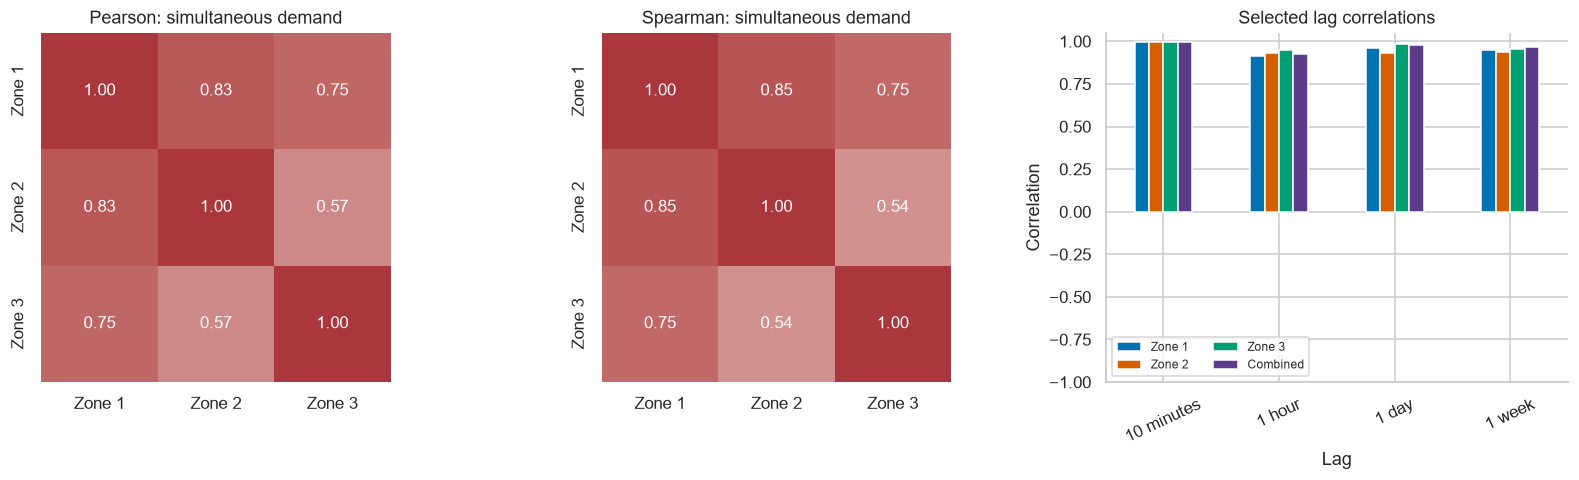

In [12]:
pearson = ts[ZONES].corr(method="pearson")
spearman = ts[ZONES].corr(method="spearman")
save_table(pearson, "20_zone_pearson_correlations")
save_table(spearman, "21_zone_spearman_correlations")
display(pearson.round(3))
display(spearman.round(3))

lag_steps = {"10 minutes": 1, "1 hour": 6, "1 day": 144, "1 week": 1008}
lag_corr = pd.DataFrame({label: {s: ts[s].autocorr(lag=lag) for s in SERIES}
                         for label, lag in lag_steps.items()})
save_table(lag_corr, "22_selected_autocorrelations")
display(lag_corr.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, matrix, title in [(axes[0], pearson, "Pearson: simultaneous demand"),
                           (axes[1], spearman, "Spearman: simultaneous demand")]:
    sns.heatmap(matrix.rename(index=LABELS, columns=LABELS), ax=ax, annot=True, fmt=".2f",
                cmap="vlag", vmin=-1, vmax=1, square=True, cbar=False)
    ax.set_title(title)
lag_corr.rename(index=LABELS).T.plot.bar(ax=axes[2], color=[COLORS[s] for s in SERIES], rot=25)
axes[2].set(title="Selected lag correlations", xlabel="Lag", ylabel="Correlation", ylim=(-1,1.05))
axes[2].legend(fontsize=8, ncol=2)
show_figure(fig, "11_zone_and_lag_correlations")

### Interpretation: Implications for Forecasting
Pearson correlations are approximately **0.835** between Zones 1 and 2, **0.751** between Zones 1 and 3, and **0.571** between Zones 2 and 3. They are positive, but not identical. Separate zone models can preserve differences hidden by the combined series.

Short-lag correlations are very high, and demand also has positive daily and weekly lag correlations. This supports testing persistence and previous-day/previous-week baselines.

For combined demand, the daily lag correlation is approximately **0.979** and the weekly lag correlation **0.966**. These are raw-series relationships, so they include shared daily and monthly structure.

It does not establish which baseline will perform best at our eventual forecast horizon. For example, a value observed ten minutes ago is unavailable for predicting a target a full day ahead from today's forecast origin.

We will construct lag features using past information only and compare every proposed model against a baseline on the same targets and horizon.

## 13. Save Headline Findings and Check Outputs
The summary below collects reproducible figures for our report and defence. The saved CSV tables preserve unrounded calculations; rounding is used only for display.

The figure index records each file and its purpose. This makes it easier to locate supporting evidence when preparing slides.

In [13]:
headlines = pd.Series({
    "observations": len(df),
    "observed_days": len(daily),
    "combined_mean": ts["total"].mean(),
    "combined_median": ts["total"].median(),
    "combined_std": ts["total"].std(),
    "typical_peak_hour": int(hourly["total"].idxmax()),
    "typical_peak_hour_mean": hourly["total"].max(),
    "typical_low_hour": int(hourly["total"].idxmin()),
    "typical_low_hour_mean": hourly["total"].min(),
    "maximum_individual_combined": ts["total"].max(),
    "minimum_individual_combined": ts["total"].min(),
    "highest_month": int(monthly["total"].idxmax()),
    "lowest_month": int(monthly["total"].idxmin()),
    "july_vs_december_pct": (monthly.loc[7,"total"] / monthly.loc[12,"total"] - 1) * 100,
    "weekend_vs_weekday_pct": gap,
}, name="value")
save_table(headlines, "23_headline_findings")
display(headlines.round(2).to_frame())

figure_names = [
    "01_daily_demand_overview", "02_demand_histograms", "03_boxplots_and_duration_curves",
    "04_hourly_profiles", "05_weekday_and_weekend_patterns", "06_monthly_mean_profiles",
    "07_monthly_distribution_of_daily_means", "08_zone_contributions",
    "09_zone_month_hour_heatmaps", "10_combined_weekday_hour_heatmap",
    "11_zone_and_lag_correlations",
]
purposes = [
    "Daily evolution and within-day range", "Demand distributions and mean versus median",
    "Zone spread and duration of demand levels", "Typical hourly means and observed IQR",
    "Weekly means and weekday/weekend hourly profiles", "Monthly means and zone differences",
    "Day-to-day variation within each month", "Overall and monthly zone composition",
    "Month-hour interaction by zone", "Weekday-hour interaction for combined demand",
    "Zone co-movement and selected lag correlations",
]
figure_index = pd.DataFrame({"figure": figure_names, "purpose": purposes})
save_table(figure_index, "24_figure_index", index=False)
for name in figure_names:
    for extension in ["png", "svg"]:
        assert (EDA_FIGURES / f"{name}.{extension}").stat().st_size > 0

pd.testing.assert_frame_equal(pd.read_parquet(clean_path), df[pd.read_parquet(clean_path).columns])
print(f"Completed: {len(figure_names)} figures, each saved as PNG and SVG.")
print("The cleaned Parquet input is unchanged.")
print("Figures:", EDA_FIGURES)
print("Tables :", EDA_TABLES)

Completed: 11 figures, each saved as PNG and SVG.
The cleaned Parquet input is unchanged.
Figures: C:\Users\banda\Desktop\MScBA\Semester_1\Descriptive Analytics & Data Visualization\Project\outputs\figures\02_demand_patterns
Tables : C:\Users\banda\Desktop\MScBA\Semester_1\Descriptive Analytics & Data Visualization\Project\outputs\tables\02_demand_patterns


,value
observations,52416.00
observed_days,364.00
combined_mean,71222.89
combined_median,69788.79
combined_std,17143.14
typical_peak_hour,20.00
typical_peak_hour_mean,98037.11
typical_low_hour,6.00
typical_low_hour_mean,50189.90
maximum_individual_combined,134208.15


## 14. Conclusions for the Team and Project Defence
1. **Demand has a clear daily pattern.** The highest combined hourly mean occurs around 20:00 and the lowest around 06:00.
2. **2017 monthly levels differ substantially.** July has the highest combined monthly mean, while December has the lowest observed monthly mean.
3. **The zones differ in size and variability.** Zone 1 has the largest average and overall contribution. Zone 3 has the greatest relative variability and a marked upper tail.
4. **Weekly patterns add context.** Sunday has the lowest weekday average, with differences that should be examined by hour rather than reduced to one overall percentage.
5. **Demand is time-dependent.** Persistence and daily/weekly lag relationships motivate baseline forecasts, subject to an agreed prediction horizon.

### Points to explain during the defence
- State the aggregation: an individual ten-minute reading, an hourly category mean, a daily mean, and a monthly mean are different quantities.
- Name the units as source units until verified; do not label summed readings as kWh.
- Explain that bands and boxplots show historical spread, not forecast uncertainty.
- A descriptive high percentile or historical maximum is not yet an operational peak definition.
- Patterns in one observed year and one city's zones cannot establish repeating seasonality, causal weather effects, or national representativeness.

### Next step: Notebook 03 — Weather Relationships
Examine temperature, humidity, wind speed, and flow measurements alongside demand. Compare simple associations with patterns conditioned on time, and distinguish contemporaneous explanation from weather information that would actually be available when forecasting.

Before modelling, agree on the forecast horizon, chronological evaluation procedure, and a peak definition whose fitted thresholds use training data only.